In [1]:
import pandas as pd

gcc = pd.read_csv("ADAP_Macula_GCC_dataset.csv")
gcc.head()

,id,time,GCC,base_age
0,1,0.000000,94,75
1,1,0.670773,93,75
2,1,1.667351,95,75
3,1,2.663929,92,75
4,2,0.000000,68,76


In [3]:
n_measurements = len(gcc)
n_patients = gcc["id"].nunique()
visits_per_patient = gcc.groupby("id").size()

print("Total measurements:", n_measurements)
print("Number of patients:", n_patients)
print("Minimum visits per patient:", visits_per_patient.min())
print("Maximum visits per patient:", visits_per_patient.max())

Total measurements: 786
Number of patients: 107
Minimum visits per patient: 4
Maximum visits per patient: 10


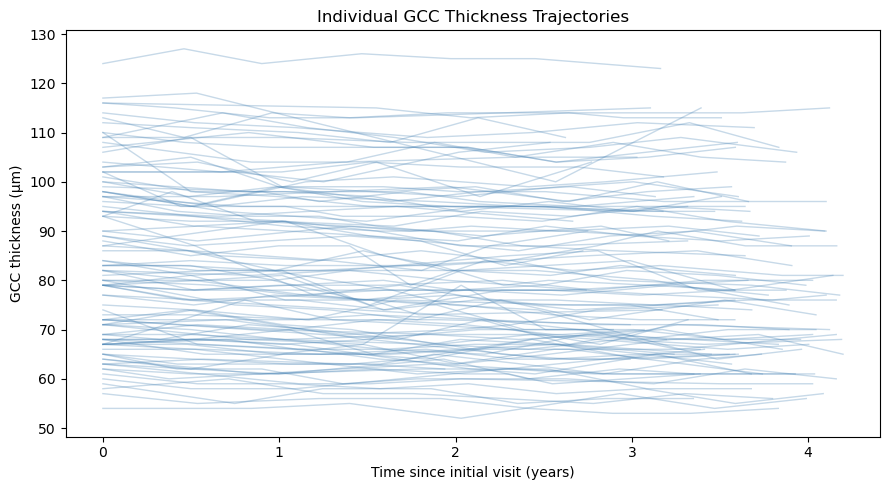

In [4]:
import matplotlib.pyplot as plt

gcc_sorted = gcc.sort_values(["id", "time"])

fig, ax = plt.subplots(figsize=(9, 5))

for patient_id, patient_data in gcc_sorted.groupby("id"):
    ax.plot(
        patient_data["time"],
        patient_data["GCC"],
        color="steelblue",
        alpha=0.3,
        linewidth=1,
    )

ax.set_title("Individual GCC Thickness Trajectories")
ax.set_xlabel("Time since initial visit (years)")
ax.set_ylabel("GCC thickness (µm)")

fig.tight_layout()
plt.show()

In [5]:
baseline_gcc = gcc.loc[gcc["time"] == 0, "GCC"]
baseline_gcc.describe().round(2)

count    107.00
mean      83.81
std       16.96
min       54.00
25%       68.50
50%       82.00
75%       97.50
max      124.00
Name: GCC, dtype: float64

In [6]:
import numpy as np

gcc_visits = gcc.assign(
    visit_year=np.floor(gcc["time"] * 2 + 0.5) / 2
)

patient_visit = (
    gcc_visits.groupby(["id", "visit_year"], as_index=False)
    .agg(patient_gcc=("GCC", "mean"))
)

visit_summary = (
    patient_visit.groupby("visit_year", as_index=False)
    .agg(
        n_patients=("id", "size"),
        mean_gcc=("patient_gcc", "mean"),
    )
)

visit_summary.round(2)

,visit_year,n_patients,mean_gcc
0,0.0,107,83.81
1,0.5,90,82.69
2,1.0,91,81.51
3,1.5,83,83.81
4,2.0,93,80.79
5,2.5,93,80.83
6,3.0,88,81.50
7,3.5,79,79.01
8,4.0,42,75.87


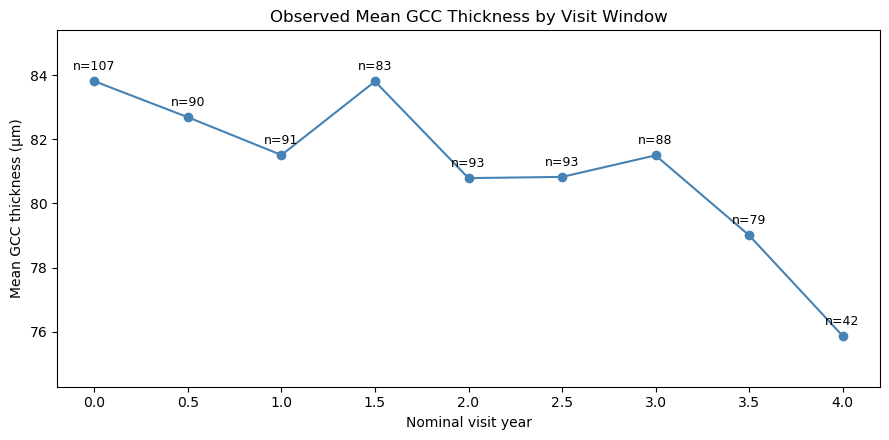

In [7]:
fig, ax = plt.subplots(figsize=(9, 4.5))

ax.plot(
    visit_summary["visit_year"],
    visit_summary["mean_gcc"],
    marker="o",
    color="steelblue",
    linewidth=1.5,
)

for visit in visit_summary.itertuples(index=False):
    ax.annotate(
        f"n={visit.n_patients}",
        (visit.visit_year, visit.mean_gcc),
        xytext=(0, 8),
        textcoords="offset points",
        ha="center",
        fontsize=9,
    )

ax.set_title("Observed Mean GCC Thickness by Visit Window")
ax.set_xlabel("Nominal visit year")
ax.set_ylabel("Mean GCC thickness (µm)")
ax.set_xticks(visit_summary["visit_year"])
ax.margins(y=0.2)

fig.tight_layout()
plt.show()

In [8]:
baseline = gcc.loc[gcc["time"] == 0, ["id", "GCC"]].rename(
    columns={"GCC": "baseline_gcc"}
)

year4 = patient_visit.loc[
    patient_visit["visit_year"] == 4, ["id", "patient_gcc"]
].rename(columns={"patient_gcc": "year4_gcc"})

paired = baseline.merge(year4, on="id", how="inner", validate="one_to_one")
paired["loss_um"] = paired["baseline_gcc"] - paired["year4_gcc"]

print("Paired patients:", len(paired))
print("Mean baseline GCC:", round(paired["baseline_gcc"].mean(), 2))
print("Mean year-4 GCC:", round(paired["year4_gcc"].mean(), 2))
print("Mean paired loss:", round(paired["loss_um"].mean(), 2))

Paired patients: 42
Mean baseline GCC: 78.81
Mean year-4 GCC: 75.87
Mean paired loss: 2.94


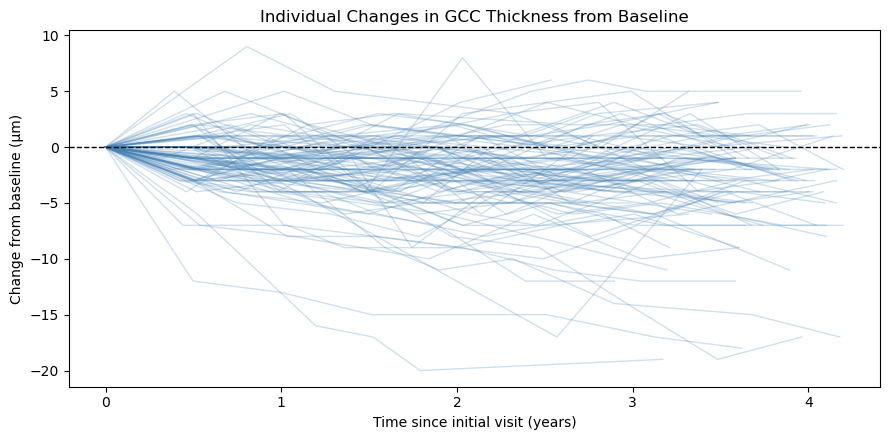

In [9]:
gcc_change = gcc_sorted.merge(baseline, on="id", validate="many_to_one")
gcc_change["change_from_baseline"] = (
    gcc_change["GCC"] - gcc_change["baseline_gcc"]
)

fig, ax = plt.subplots(figsize=(9, 4.5))

for patient_id, visits in gcc_change.groupby("id"):
    ax.plot(
        visits["time"],
        visits["change_from_baseline"],
        color="steelblue",
        alpha=0.25,
        linewidth=1,
    )

ax.axhline(0, color="black", linestyle="--", linewidth=1)
ax.set_title("Individual Changes in GCC Thickness from Baseline")
ax.set_xlabel("Time since initial visit (years)")
ax.set_ylabel("Change from baseline (µm)")

fig.tight_layout()
plt.show()

##Part 1 (b)

線性模型

In [10]:
import statsmodels.formula.api as smf

linear_model = smf.mixedlm(
    "GCC ~ time",
    data=gcc_sorted,
    groups="id",
    re_formula="1 + time",
)

linear_fit = linear_model.fit(reml=False, method="lbfgs")

print("Converged:", linear_fit.converged)
print("Fixed effects:")
print(linear_fit.fe_params.round(3))

Converged: True
Fixed effects:
Intercept    83.265
time         -0.821
dtype: float64


比較線性與二次時間趨勢
概似比檢定（likelihood ratio test, LRT）

In [ ]:
from scipy.stats import chi2

quadratic_model = smf.mixedlm(
    "GCC ~ time + I(time ** 2)",
    data=gcc_sorted,
    groups="id",
    re_formula="1 + time",
)

quadratic_fit = quadratic_model.fit(reml=False, method="lbfgs")

print("Quadratic model converged:", quadratic_fit.converged)
print("Fixed effects:")
print(quadratic_fit.fe_params.round(3))

if linear_fit.converged and quadratic_fit.converged:
    lr_statistic = 2 * (quadratic_fit.llf - linear_fit.llf)
    p_value = chi2.sf(lr_statistic, df=1)

    print(f"Likelihood ratio statistic: {lr_statistic:.3f}")
    print(f"P-value: {p_value:.6f}")